In [1]:
import sys
from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Notebook berada di folder notebooks/
PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "src").exists():
    # Fallback jika kernel dijalankan dari root project
    PROJECT_ROOT = Path.cwd().resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import CONFIG
from src.preprocessing import (
    load_data, validate_columns, clean_data, print_cleaning_summary
)
from src.rfm import calculate_customer_rfm
from src.clustering import (
    standardize_features, run_kmeans_for_multiple_k
)
from src.evaluation import (
    calculate_clustering_metrics, rank_k_candidates, select_optimal_k
)
from src.visualization import (
    plot_silhouette_by_k, plot_dbi_by_k, plot_chi_by_k, plot_clusters_pca
)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROJECT_ROOT / "data" / "online_retail_II.xlsx"
SHEET_NAME = CONFIG.sheet_name
RANDOM_STATE = CONFIG.random_state
CANDIDATE_K = tuple(CONFIG.candidate_k)
N_INIT = CONFIG.n_init
MAX_ITER = CONFIG.max_iter

FEATURE_COLS = ["Recency", "Frequency", "Monetary"]
LOG_FEATURES = ("Frequency", "Monetary")
LOG_TRANSFORM = CONFIG.log_transform

print("Project root :", PROJECT_ROOT)
print("Data path    :", DATA_PATH)
print("Sheet        :", SHEET_NAME)
print("Output dir   :", OUTPUT_DIR)
print("Fitur        :", FEATURE_COLS)
print("Log transform:", LOG_TRANSFORM, LOG_FEATURES)


Project root : D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation
Data path    : D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\data\online_retail_II.xlsx
Sheet        : Year 2010-2011
Output dir   : D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs
Fitur        : ['Recency', 'Frequency', 'Monetary']
Log transform: True ('Frequency', 'Monetary')


In [2]:
raw = load_data(DATA_PATH, SHEET_NAME)

print("Raw shape:", raw.shape)
display(raw.head())
display(raw.info())

Raw shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  540456 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[ns]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


None

In [3]:
df_valid = validate_columns(raw)

print("Tipe data:")
display(df_valid.dtypes.to_frame("dtype"))

print("\\nMissing values:")
display(df_valid.isna().sum().to_frame("missing_values"))

print("\\nRentang tanggal:")
print(df_valid["InvoiceDate"].min(), "hingga", df_valid["InvoiceDate"].max())

print("\\nJumlah baris duplikat identik:", df_valid.duplicated().sum())
print("Cancellation invoice:", df_valid["InvoiceNo"].astype(str).str.upper().str.startswith("C").sum())
print("Quantity <= 0:", (df_valid["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df_valid["UnitPrice"] <= 0).sum())

display(df_valid[["Quantity", "UnitPrice"]].describe().T)


Tipe data:


,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


\nMissing values:


,missing_values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


\nRentang tanggal:
2010-12-01 08:26:00 hingga 2011-12-09 12:50:00
\nJumlah baris duplikat identik: 5268
Cancellation invoice: 9288
Quantity <= 0: 10624
UnitPrice <= 0: 2517


,count,mean,std,min,25%,50%,75%,max
Quantity,"541,910.00",9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
UnitPrice,"541,910.00",4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"


In [4]:
cleaned, cleaning_log = clean_data(
    df_valid,
    remove_non_product=CONFIG.remove_non_product
)

print_cleaning_summary(cleaning_log)
display(cleaning_log)
display(cleaned.head())

# Simpan hasil preprocessing
cleaned.to_csv(OUTPUT_DIR / "cleaned_data_rfm.csv", index=False)
cleaning_log.to_csv(OUTPUT_DIR / "cleaning_log_rfm.csv", index=False)

print("Data bersih:", cleaned.shape)
print("Jumlah pelanggan:", cleaned["CustomerID"].nunique())
print("Jumlah invoice unik:", cleaned["InvoiceNo"].nunique())


PREPROCESSING SUMMARY
Rows before      : 541,910
Rows after       : 392,693
Customers before : 4,372
Customers after  : 4,338
------------------------------------------------------------
remove_invalid_invoice_date         removed:          0
remove_missing_customer_id          removed:    135,080
remove_duplicate_rows               removed:      5,225
remove_cancellation                 removed:      8,872
remove_non_positive_quantity        removed:          0
remove_non_positive_unit_price      removed:         40


,step,rows_before,rows_after,rows_removed,customers_after
0,initial,541910,541910,0,4372
1,remove_invalid_invoice_date,541910,541910,0,4372
2,remove_missing_customer_id,541910,406830,135080,4372
3,remove_duplicate_rows,406830,401605,5225,4372
4,remove_cancellation,401605,392733,8872,4339
5,remove_non_positive_quantity,392733,392733,0,4339
6,remove_non_positive_unit_price,392733,392693,40,4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Data bersih: (392693, 9)
Jumlah pelanggan: 4338
Jumlah invoice unik: 18532


In [5]:
reference_date = cleaned["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = calculate_customer_rfm(
    cleaned,
    reference_date=reference_date
)

# Validasi hasil RFM
assert rfm["CustomerID"].is_unique, "CustomerID seharusnya unik pada tabel RFM."
assert (rfm[["Recency", "Frequency", "Monetary"]] >= 0).all().all()
assert rfm[FEATURE_COLS].notna().all().all()

print("Reference date:", reference_date)
print("Jumlah pelanggan:", len(rfm))
display(rfm.head())
display(rfm[FEATURE_COLS].describe().T)

rfm.to_csv(OUTPUT_DIR / "customer_rfm.csv", index=False)


Reference date: 2011-12-10 00:00:00
Jumlah pelanggan: 4338


,CustomerID,LastPurchaseDate,Recency,Frequency,Monetary
0,12346,2011-01-18 10:01:00,325,1,"77,183.60"
1,12347,2011-12-07 15:52:00,2,7,"4,310.00"
2,12348,2011-09-25 13:13:00,75,4,"1,797.24"
3,12349,2011-11-21 09:51:00,18,1,"1,757.55"
4,12350,2011-02-02 16:01:00,310,1,334.40


,count,mean,std,min,25%,50%,75%,max
Recency,"4,338.00",92.06,100.01,0.00,17.00,50.00,141.75,373.00
Frequency,"4,338.00",4.27,7.70,1.00,1.00,2.00,5.00,209.00
Monetary,"4,338.00","2,048.69","8,985.23",3.75,306.48,668.57,"1,660.60","280,206.02"


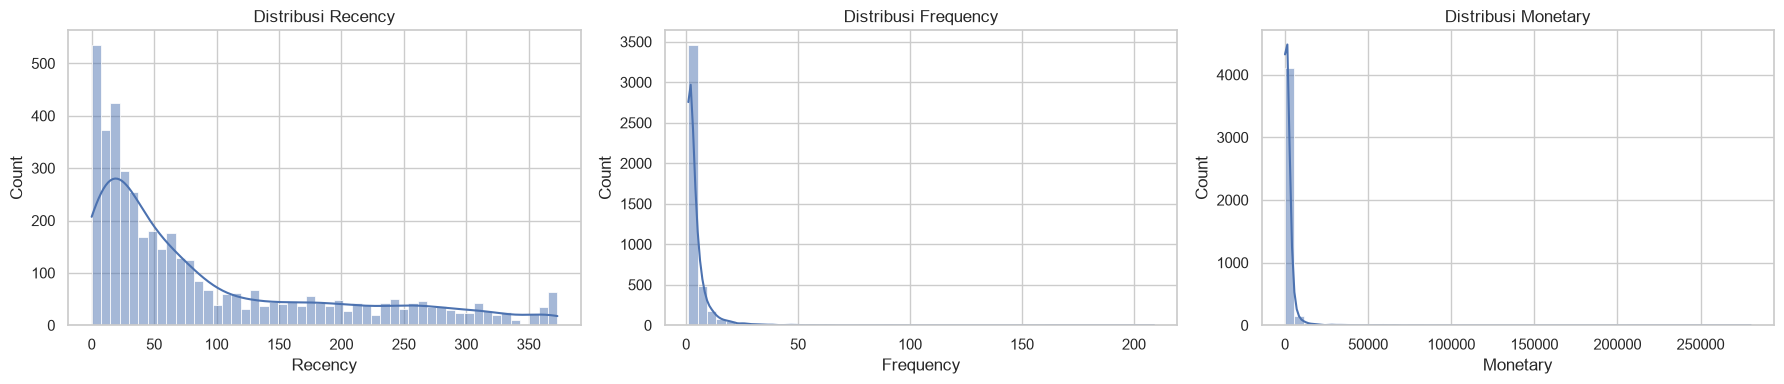

,Skewness
Recency,1.25
Frequency,12.07
Monetary,19.34


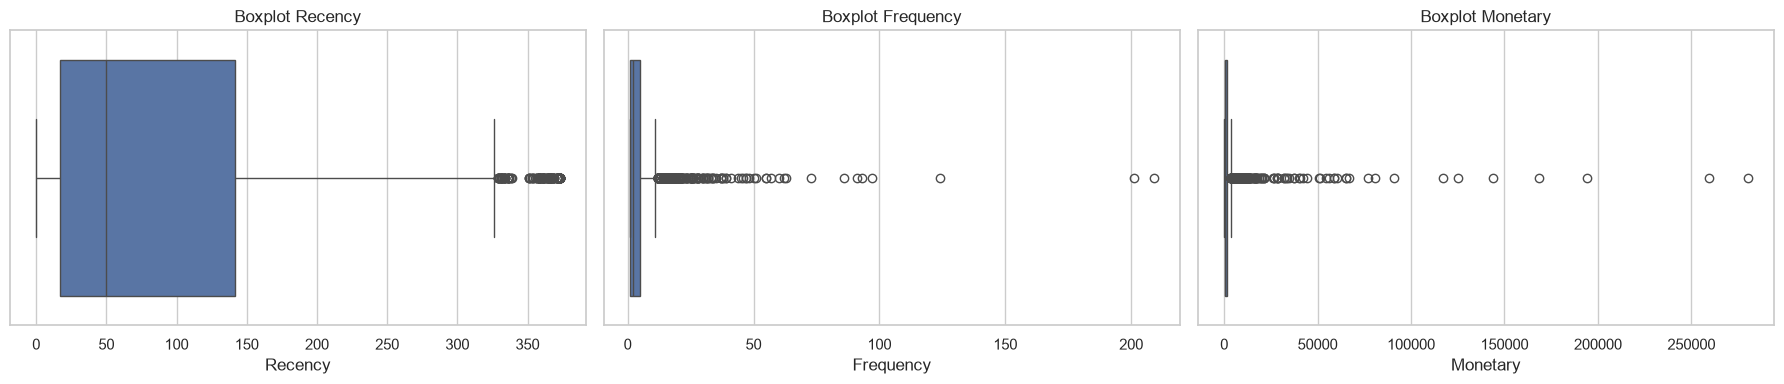

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, FEATURE_COLS):
    sns.histplot(rfm[col], bins=50, kde=True, ax=ax)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rfm_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

display(rfm[FEATURE_COLS].skew().to_frame("Skewness"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, FEATURE_COLS):
    sns.boxplot(x=rfm[col], ax=ax)
    ax.set_title(f"Boxplot {col}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rfm_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()


In [7]:
print("Korelasi Spearman:")
display(rfm[FEATURE_COLS].corr(method="spearman").round(3))

print("Korelasi Pearson:")
display(rfm[FEATURE_COLS].corr(method="pearson").round(3))


Korelasi Spearman:


,Recency,Frequency,Monetary
Recency,1.00,-0.56,-0.48
Frequency,-0.56,1.00,0.81
Monetary,-0.48,0.81,1.00


Korelasi Pearson:


,Recency,Frequency,Monetary
Recency,1.00,-0.26,-0.12
Frequency,-0.26,1.00,0.55
Monetary,-0.12,0.55,1.00


In [8]:
X_scaled, scaler, X_pre = standardize_features(
    rfm,
    FEATURE_COLS,
    log_transform=LOG_TRANSFORM,
    log_features=LOG_FEATURES
)

print("Skewness sebelum dan sesudah transformasi + scaling:")
display(pd.DataFrame({
    "before": rfm[FEATURE_COLS].skew(),
    "after": X_scaled.skew()
}).round(3))

assert np.isfinite(X_scaled.to_numpy()).all()
assert np.allclose(X_scaled.mean(), 0, atol=1e-8)
assert np.allclose(X_scaled.std(ddof=0), 1, atol=1e-8)

print("Pemeriksaan standardisasi: OK")
display(X_scaled.describe().round(3))

joblib.dump(scaler, OUTPUT_DIR / "scaler_rfm.joblib")
scaled_output = X_scaled.copy()
scaled_output.insert(0, "CustomerID", rfm["CustomerID"].values)
scaled_output.to_csv(OUTPUT_DIR / "customer_rfm_scaled.csv", index=False)


Skewness sebelum dan sesudah transformasi + scaling:


,before,after
Recency,1.25,1.25
Frequency,12.07,1.21
Monetary,19.34,0.40


Pemeriksaan standardisasi: OK


,Recency,Frequency,Monetary
count,"4,338.00","4,338.00","4,338.00"
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-0.92,-0.95,-4.00
25%,-0.75,-0.95,-0.68
50%,-0.42,-0.36,-0.07
75%,0.50,0.65,0.66
max,2.81,5.86,4.73


In [9]:
print("Kandidat K:", list(CANDIDATE_K))
print(f"n_init={N_INIT}, random_state={RANDOM_STATE}, max_iter={MAX_ITER}")

kmeans_results = run_kmeans_for_multiple_k(
    X_scaled,
    CANDIDATE_K,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
    max_iter=MAX_ITER
)


Kandidat K: [2, 3, 4, 5, 6, 7, 8, 9, 10]
n_init=20, random_state=42, max_iter=300
  K=2  selesai | inertia=6,874.0
  K=3  selesai | inertia=4,299.2
  K=4  selesai | inertia=3,242.9
  K=5  selesai | inertia=2,760.7
  K=6  selesai | inertia=2,396.8
  K=7  selesai | inertia=2,167.0
  K=8  selesai | inertia=1,961.4
  K=9  selesai | inertia=1,819.0
  K=10 selesai | inertia=1,688.2


In [10]:
metrics_df = calculate_clustering_metrics(X_scaled, kmeans_results)
metrics_df.to_csv(OUTPUT_DIR / "clustering_evaluation_rfm.csv", index=False)
display(metrics_df.round(4))

print("Silhouette terbaik:", int(metrics_df.loc[metrics_df["Silhouette"].idxmax(), "K"]))
print("DBI terbaik       :", int(metrics_df.loc[metrics_df["DBI"].idxmin(), "K"]))
print("CHI terbaik       :", int(metrics_df.loc[metrics_df["CHI"].idxmax(), "K"]))


,K,Silhouette,DBI,CHI
0,2,0.41,0.92,"3,873.06"
1,3,0.42,0.83,"4,393.71"
2,4,0.38,0.86,"4,352.87"
3,5,0.34,0.94,"4,023.24"
4,6,0.33,0.97,"3,837.96"
5,7,0.30,1.03,"3,613.25"
6,8,0.30,1.00,"3,485.62"
7,9,0.28,1.03,"3,330.34"
8,10,0.28,1.02,"3,226.30"


Silhouette terbaik: 3
DBI terbaik       : 3
CHI terbaik       : 3


In [11]:
ranked_df = rank_k_candidates(
    metrics_df,
    weights={"Silhouette": 1.0, "DBI": 1.0, "CHI": 1.0}
)
selected_k, ranked_df = select_optimal_k(ranked_df)

ranked_df.to_csv(OUTPUT_DIR / "clustering_k_ranking_rfm.csv", index=False)

print(f"K terpilih berdasarkan multi-metric ranking: {selected_k}")
display(ranked_df.round(4))


K terpilih berdasarkan multi-metric ranking: 3


,K,Silhouette,DBI,CHI,Rank_Silhouette,Rank_DBI,Rank_CHI,TotalRank
0,3,0.42,0.83,"4,393.71",1.00,1.00,1.00,3.00
1,4,0.38,0.86,"4,352.87",3.00,2.00,2.00,7.00
2,2,0.41,0.92,"3,873.06",2.00,3.00,4.00,9.00
3,5,0.34,0.94,"4,023.24",4.00,4.00,3.00,11.00
4,6,0.33,0.97,"3,837.96",5.00,5.00,5.00,15.00
5,8,0.30,1.00,"3,485.62",6.00,6.00,7.00,19.00
6,7,0.30,1.03,"3,613.25",7.00,8.00,6.00,21.00
7,10,0.28,1.02,"3,226.30",8.00,7.00,9.00,24.00
8,9,0.28,1.03,"3,330.34",9.00,9.00,8.00,26.00


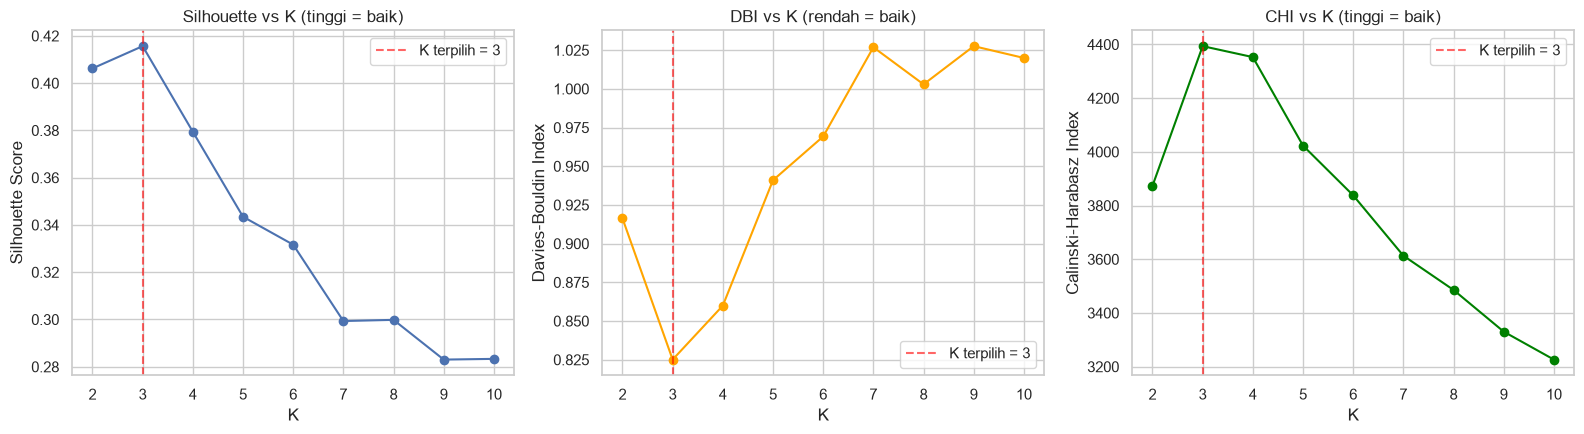

Garis merah putus-putus = K terpilih (K=3)


In [22]:
from src.visualization import plot_silhouette_by_k, plot_dbi_by_k, plot_chi_by_k, plot_clusters_pca

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_silhouette_by_k(metrics_df, selected_k, ax=axes[0])
plot_dbi_by_k(metrics_df, selected_k, ax=axes[1])
plot_chi_by_k(metrics_df, selected_k, ax=axes[2])
plt.tight_layout()
plt.savefig(CONFIG.output_dir / "evaluation_metrics_by_k.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Garis merah putus-putus = K terpilih (K={selected_k})")

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

STABILITY_SEEDS = CONFIG.stability_seeds
stability_rows = []
reference_labels = None

for seed in STABILITY_SEEDS:
    model_seed = KMeans(
        n_clusters=selected_k,
        random_state=seed,
        n_init=N_INIT,
        max_iter=MAX_ITER
    )
    labels_seed = model_seed.fit_predict(X_scaled)

    if reference_labels is None:
        reference_labels = labels_seed

    ari = adjusted_rand_score(reference_labels, labels_seed)
    stability_rows.append({
        "Seed": seed,
        "Inertia": model_seed.inertia_,
        "ARI_vs_first_seed": ari
    })

stability_df = pd.DataFrame(stability_rows)
stability_df.to_csv(OUTPUT_DIR / "cluster_stability_rfm.csv", index=False)
display(stability_df.round(4))

print("Mean ARI:", round(stability_df["ARI_vs_first_seed"].mean(), 4))
print("Catatan: seed pertama dibandingkan dengan dirinya sendiri sehingga ARI-nya 1.")


,Seed,Inertia,ARI_vs_first_seed
0,0,"4,299.19",1.00
1,1,"4,299.18",1.00
2,2,"4,299.20",1.00
3,3,"4,299.20",1.00
4,4,"4,299.20",1.00
5,5,"4,299.18",1.00
6,6,"4,299.19",1.00
7,7,"4,299.20",1.00
8,8,"4,299.19",1.00
9,9,"4,299.20",1.00


Mean ARI: 0.9989
Catatan: seed pertama dibandingkan dengan dirinya sendiri sehingga ARI-nya 1.


In [13]:
final_model = KMeans(
    n_clusters=selected_k,
    random_state=RANDOM_STATE,
    n_init=N_INIT,
    max_iter=MAX_ITER
)
final_labels = final_model.fit_predict(X_scaled)

rfm_clustered = rfm.copy()
rfm_clustered["Cluster"] = final_labels

print("Jumlah pelanggan per cluster:")
display(rfm_clustered["Cluster"].value_counts().sort_index().to_frame("NumCustomers"))


Jumlah pelanggan per cluster:


,NumCustomers
Cluster,
0,2037
1,981
2,1320


In [14]:
cluster_summary = (
    rfm_clustered.groupby("Cluster")
    .agg(
        NumCustomers=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean"),
        MedianRecency=("Recency", "median"),
        MedianFrequency=("Frequency", "median"),
        MedianMonetary=("Monetary", "median"),
        TotalMonetary=("Monetary", "sum")
    )
    .reset_index()
)

cluster_summary["PctCustomers"] = (
    cluster_summary["NumCustomers"] / len(rfm_clustered) * 100
)

cluster_summary = cluster_summary.sort_values("Cluster").reset_index(drop=True)
display(cluster_summary.round(2))

cluster_summary.to_csv(OUTPUT_DIR / "cluster_summary_rfm.csv", index=False)


,Cluster,NumCustomers,AvgRecency,AvgFrequency,AvgMonetary,MedianRecency,MedianFrequency,MedianMonetary,TotalMonetary,PctCustomers
0,0,2037,54.25,2.05,612.72,45.00,2.00,508.80,"1,248,107.72",46.96
1,1,981,254.62,1.39,397.17,252.00,1.00,290.51,"389,626.80",22.61
2,2,1320,29.60,9.84,"5,492.04",17.00,7.00,"2,570.50","7,249,492.37",30.43


In [15]:
profile = cluster_summary.copy()

recency_rank = profile["AvgRecency"].rank(ascending=True)
frequency_rank = profile["AvgFrequency"].rank(ascending=False)
monetary_rank = profile["AvgMonetary"].rank(ascending=False)

profile["BusinessProfileScore"] = (
    frequency_rank + monetary_rank + recency_rank
)

profile = profile.sort_values(
    ["AvgFrequency", "AvgMonetary", "AvgRecency"],
    ascending=[False, False, True]
).reset_index(drop=True)

if len(profile) == 3:
    profile["Segment"] = ["High Value", "Moderate Activity", "Low Activity"]
else:
    profile["Segment"] = [f"Segment {i+1}" for i in range(len(profile))]

display(profile[[
    "Cluster", "Segment", "NumCustomers", "PctCustomers",
    "AvgRecency", "AvgFrequency", "AvgMonetary", "TotalMonetary"
]].round(2))

segment_map = dict(zip(profile["Cluster"], profile["Segment"]))
rfm_clustered["Segment"] = rfm_clustered["Cluster"].map(segment_map)


,Cluster,Segment,NumCustomers,PctCustomers,AvgRecency,AvgFrequency,AvgMonetary,TotalMonetary
0,2,High Value,1320,30.43,29.60,9.84,"5,492.04","7,249,492.37"
1,0,Moderate Activity,2037,46.96,54.25,2.05,612.72,"1,248,107.72"
2,1,Low Activity,981,22.61,254.62,1.39,397.17,"389,626.80"


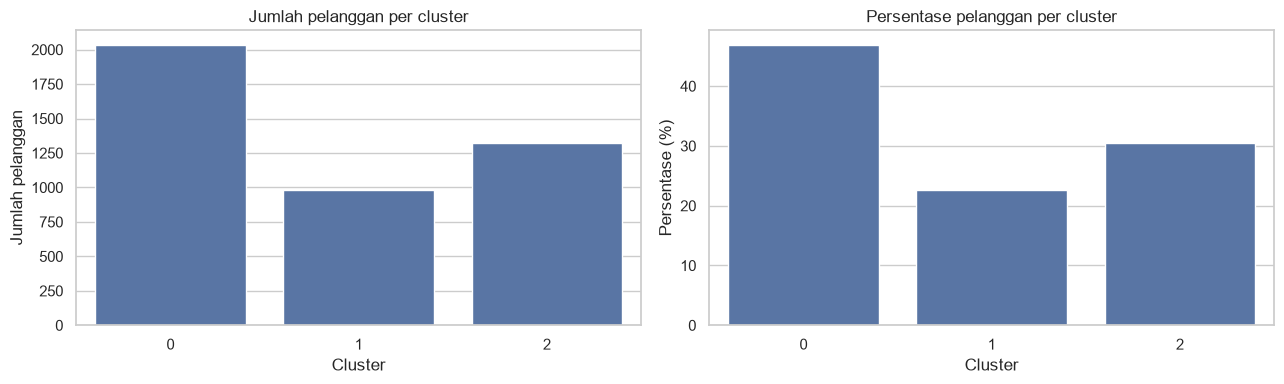

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data=cluster_summary, x="Cluster", y="NumCustomers", ax=axes[0])
axes[0].set_title("Jumlah pelanggan per cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Jumlah pelanggan")

sns.barplot(data=cluster_summary, x="Cluster", y="PctCustomers", ax=axes[1])
axes[1].set_title("Persentase pelanggan per cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Persentase (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cluster_sizes_rfm.png", dpi=150, bbox_inches="tight")
plt.show()


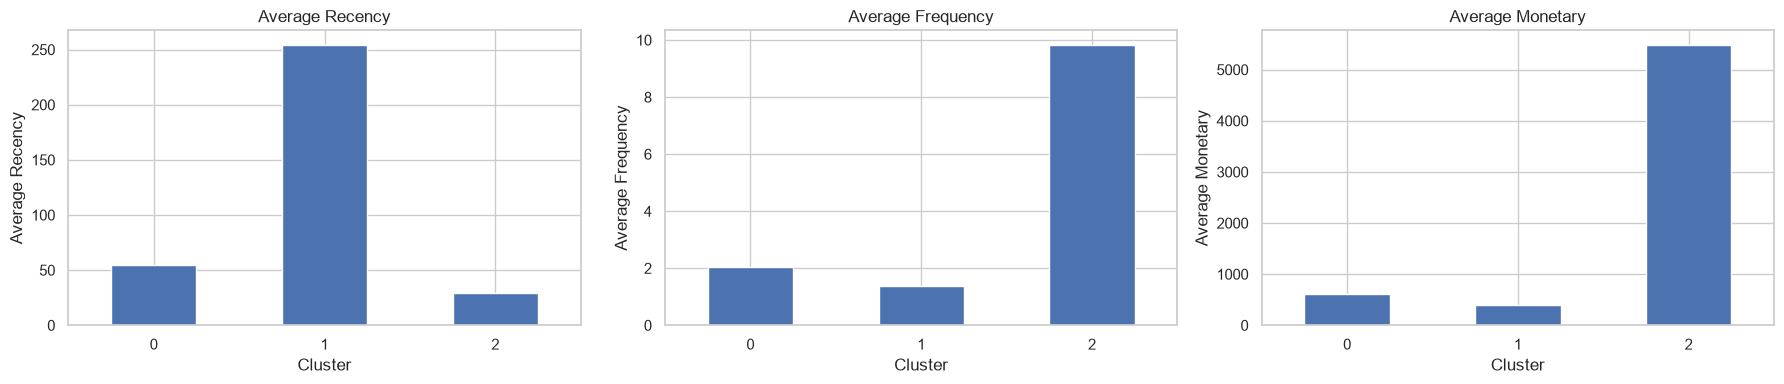

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
plot_data = cluster_summary.set_index("Cluster")

for ax, col, title in zip(
    axes,
    ["AvgRecency", "AvgFrequency", "AvgMonetary"],
    ["Average Recency", "Average Frequency", "Average Monetary"]
):
    plot_data[col].plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Cluster")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rfm_profile_by_cluster.png", dpi=150, bbox_inches="tight")
plt.show()


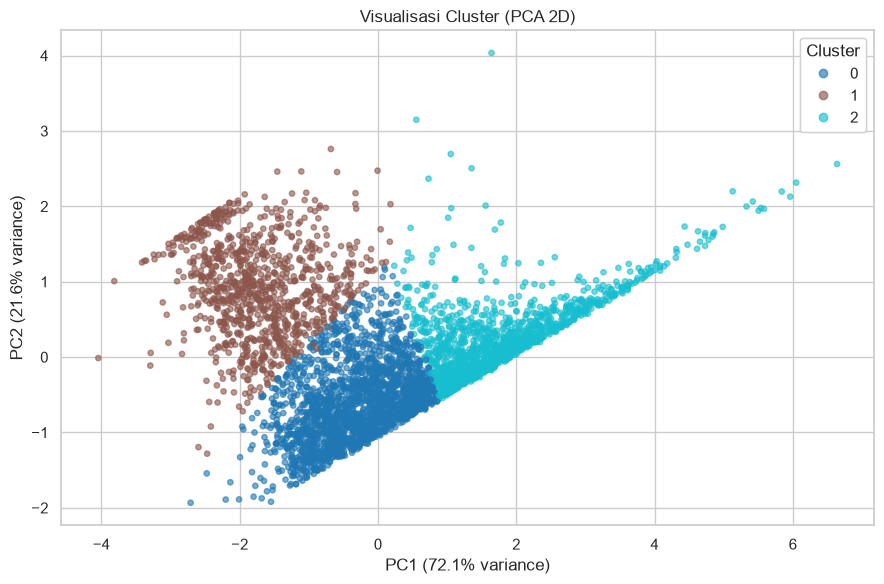

Total variance yang dijelaskan dua komponen PCA: 93.65% (PC1=72.08%, PC2=21.57%)


In [18]:
fig, ax = plt.subplots(figsize=(9, 6))
ax, explained_var = plot_clusters_pca(
    X_scaled,
    final_labels,
    random_state=RANDOM_STATE,
    ax=ax
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "clusters_pca_rfm.png", dpi=150, bbox_inches="tight")
plt.show()

print(
    f"Total variance yang dijelaskan dua komponen PCA: {explained_var.sum():.2%} "
    f"(PC1={explained_var[0]:.2%}, PC2={explained_var[1]:.2%})"
)


In [19]:
rfm_clustered.to_csv(OUTPUT_DIR / "customer_segmentation_rfm.csv", index=False)

centroids = pd.DataFrame(
    final_model.cluster_centers_,
    columns=FEATURE_COLS
)
centroids.insert(0, "Cluster", range(selected_k))
centroids.to_csv(OUTPUT_DIR / "cluster_centroids_scaled_rfm.csv", index=False)

joblib.dump(final_model, OUTPUT_DIR / "kmeans_rfm.joblib")

print("Seluruh output RFM tersimpan di:", OUTPUT_DIR)
print("\\nFile output utama:")
for path in sorted(OUTPUT_DIR.glob("*rfm*")):
    print("-", path.name)


Seluruh output RFM tersimpan di: D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs
\nFile output utama:
- cleaned_data_rfm.csv
- cleaning_log_rfm.csv
- cluster_centroids_scaled_rfm.csv
- cluster_sizes_rfm.png
- cluster_stability_rfm.csv
- cluster_summary_rfm.csv
- clustering_evaluation_rfm.csv
- clustering_k_ranking_rfm.csv
- clusters_pca_rfm.png
- customer_rfm.csv
- customer_rfm_scaled.csv
- customer_segmentation_rfm.csv
- kmeans_rfm.joblib
- rfm_boxplots.png
- rfm_distributions.png
- rfm_profile_by_cluster.png
- scaler_rfm.joblib


In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import numpy as np

STABILITY_SEEDS = [11, 21, 42, 52, 62]
FINAL_K = 3
N_INIT = 10

In [21]:
seed_labels = {}

for seed in STABILITY_SEEDS:
    model = KMeans(n_clusters=FINAL_K, random_state=seed, n_init=N_INIT)
    seed_labels[seed] = model.fit_predict(X_scaled)

stability_rows = []
seeds = list(seed_labels.keys())

for i in range(len(seeds)):
    for j in range(i + 1, len(seeds)):
        s1, s2 = seeds[i], seeds[j]
        stability_rows.append({
            "Seed_1": s1,
            "Seed_2": s2,
            "ARI": adjusted_rand_score(seed_labels[s1], seed_labels[s2])
        })

stability_df = pd.DataFrame(stability_rows)
display(stability_df.round(4))
print("Mean ARI:", round(stability_df["ARI"].mean(), 4))
print("Minimum ARI:", round(stability_df["ARI"].min(), 4))

,Seed_1,Seed_2,ARI
0,11,21,1.00
1,11,42,1.00
2,11,52,1.00
3,11,62,1.00
4,21,42,1.00
5,21,52,1.00
6,21,62,1.00
7,42,52,1.00
8,42,62,1.00
9,52,62,1.00


Mean ARI: 0.9993
Minimum ARI: 0.9985
